# Data Definition and Schema Design (CREATE, ALTER)

The **Data Definition Language (DDL)** creates and changes the structure of a database: tables, columns, types, keys and constraints. A good schema makes correct data easy to store and wrong data impossible to store.

**After this lesson you can:**

1. Select PostgreSQL data types for each kind of value.
2. Create tables with keys, defaults and constraints.
3. Change a schema with `ALTER TABLE` and understand migrations.
4. Explain the difference between `DROP`, `TRUNCATE` and `DELETE`.

The lesson works in the separate `course` database, so the Chinook data stays unchanged.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads and loads the sample data

engine = create_engine(datasets.ensure_chinook())  # starts PostgreSQL in Docker and loads Chinook on first use

def q(sql: str, **params) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

lab = create_engine(datasets.POSTGRES_URL.format(db="course"))   # a separate database for experiments

def run(sql: str) -> None:
    """Execute SQL statements (DDL/DML) in the lab database, in one transaction."""
    with lab.begin() as conn:
        if "$$" in sql:                       # function bodies contain ";" -> send the whole script at once
            conn.execute(text(sql))
            return
        for stmt in [s for s in sql.split(";") if s.strip()]:
            conn.execute(text(stmt))

def lq(sql: str, **params) -> pd.DataFrame:
    with lab.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

## 1. Data Types

| Kind of value | PostgreSQL type | Notes |
| :--- | :--- | :--- |
| whole numbers | `integer`, `bigint` | `bigint` for ids that can exceed 2.1 billion |
| generated ids | `integer GENERATED ALWAYS AS IDENTITY` | the modern form of `serial` |
| money, exact decimals | `numeric(10, 2)` | never `float` for money |
| measurements | `double precision` | approximate |
| text | `text`, `varchar(n)` | in PostgreSQL both have the same speed |
| true/false | `boolean` | |
| dates and times | `date`, `timestamptz` | `timestamptz` stores an absolute point in time |
| identifiers | `uuid` | globally unique ids |
| semi-structured data | `jsonb` | Lesson 14 |

In [2]:
print(lq("SELECT (0.1::float8 + 0.2::float8)::text AS float_sum, 0.1::float8 + 0.2::float8 = 0.3 AS float_equals_0_3, "
         "(0.1::numeric + 0.2::numeric)::text AS numeric_sum, 0.1::numeric + 0.2::numeric = 0.3 AS numeric_equals_0_3"))
print(lq("SELECT pg_column_size(1::smallint) AS smallint_bytes, pg_column_size(1::integer) AS int_bytes, "
         "pg_column_size(1::bigint) AS bigint_bytes, pg_column_size(now()) AS timestamptz_bytes"))

             float_sum  float_equals_0_3 numeric_sum  numeric_equals_0_3
0  0.30000000000000004             False         0.3                True
   smallint_bytes  int_bytes  bigint_bytes  timestamptz_bytes
0               2          4             8                  8


`float` cannot represent 0.1 exactly, so the sum is not exactly 0.3. `numeric` is exact. Use `numeric` for money.

## 2. Create Tables with Constraints

The schema below is for a small online course platform: students, courses and enrollments (many-to-many).

In [3]:
run("""
DROP TABLE IF EXISTS enrollment;
DROP TABLE IF EXISTS course;
DROP TABLE IF EXISTS student;

CREATE TABLE student (
    student_id   integer GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
    email        text NOT NULL UNIQUE CHECK (email LIKE '%_@_%._%'),
    full_name    text NOT NULL,
    country      char(2) NOT NULL DEFAULT 'TR',
    created_at   timestamptz NOT NULL DEFAULT now()
);

CREATE TABLE course (
    course_id    integer GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
    code         text NOT NULL UNIQUE,
    title        text NOT NULL,
    price        numeric(8, 2) NOT NULL CHECK (price >= 0)
);

CREATE TABLE enrollment (
    student_id   integer NOT NULL REFERENCES student (student_id) ON DELETE CASCADE,
    course_id    integer NOT NULL REFERENCES course (course_id) ON DELETE RESTRICT,
    enrolled_on  date NOT NULL DEFAULT current_date,
    progress     smallint NOT NULL DEFAULT 0 CHECK (progress BETWEEN 0 AND 100),
    PRIMARY KEY (student_id, course_id)
)
""")
run("""
INSERT INTO student (email, full_name, country) VALUES ('ayse@example.com', 'Ayse Kaya', 'TR'),
       ('liam@example.com', 'Liam Smith', 'IE'), ('mei@example.com', 'Mei Chen', 'SG');
INSERT INTO course (code, title, price) VALUES ('SQL101', 'SQL Basics', 49), ('PY201', 'Python for Data', 79);
INSERT INTO enrollment (student_id, course_id, progress) VALUES (1, 1, 100), (1, 2, 40), (2, 1, 75), (3, 2, 10)
""")
lq("SELECT s.full_name, c.code, e.progress FROM enrollment e JOIN student s USING (student_id) "
   "JOIN course c USING (course_id) ORDER BY 1, 2")

,full_name,code,progress
0,Ayse Kaya,PY201,40
1,Ayse Kaya,SQL101,100
2,Liam Smith,SQL101,75
3,Mei Chen,PY201,10


## 3. The Schema Rejects Bad Data

In [4]:
bad = {
    "invalid e-mail": "INSERT INTO student (email, full_name) VALUES ('not-an-email', 'X')",
    "negative price": "INSERT INTO course (code, title, price) VALUES ('BAD1', 'Bad', -5)",
    "progress 120%": "INSERT INTO enrollment (student_id, course_id, progress) VALUES (2, 2, 120)",
    "duplicate enrollment": "INSERT INTO enrollment (student_id, course_id) VALUES (1, 1)",
    "delete a course in use": "DELETE FROM course WHERE code = 'SQL101'",
}
results = []
for name, sql in bad.items():
    try:
        run(sql)
        results.append((name, "accepted"))
    except Exception as err:
        results.append((name, type(err.orig).__name__))
pd.DataFrame(results, columns=["attempt", "result"])

,attempt,result
0,invalid e-mail,CheckViolation
1,negative price,CheckViolation
2,progress 120%,CheckViolation
3,duplicate enrollment,UniqueViolation
4,delete a course in use,ForeignKeyViolation


## 4. Change the Schema: `ALTER TABLE` and Migrations

Schemas change over time. `ALTER TABLE` adds, renames or drops columns and constraints. In real projects, every change is a **migration**: a numbered script in Git (tools: Alembic, Flyway, Liquibase, dbt for analytics models). Migrations run in order, so every environment (laptop, test, production) has the same schema.

Some changes are **backwards compatible** (add a nullable column) and some are **breaking** (rename or drop a column that code still reads).

In [5]:
run("ALTER TABLE course ADD COLUMN level text NOT NULL DEFAULT 'beginner' CHECK (level IN ('beginner', 'intermediate', 'advanced'))")
run("ALTER TABLE student RENAME COLUMN full_name TO display_name")
run("ALTER TABLE course ADD COLUMN hours numeric(4, 1)")
run("UPDATE course SET hours = CASE code WHEN 'SQL101' THEN 6 ELSE 12.5 END, level = CASE code WHEN 'PY201' THEN 'intermediate' ELSE level END")
cols = lq("""SELECT table_name, column_name, data_type, is_nullable, column_default
             FROM information_schema.columns WHERE table_name IN ('student', 'course') ORDER BY table_name, ordinal_position""")
cols

,table_name,column_name,data_type,is_nullable,column_default
0,course,course_id,integer,NO,NaN
1,course,code,text,NO,NaN
2,course,title,text,NO,NaN
3,course,price,numeric,NO,NaN
4,course,level,text,NO,'beginner'::text
5,course,hours,numeric,YES,NaN
6,student,student_id,integer,NO,NaN
7,student,email,text,NO,NaN
8,student,display_name,text,NO,NaN
9,student,country,character,NO,'TR'::bpchar


## 5. `DROP`, `TRUNCATE`, `DELETE`

| Command | Removes | Speed | Can roll back | Fires row triggers |
| :--- | :--- | :--- | :-: | :-: |
| `DELETE FROM t WHERE ...` | selected rows | slow for many rows | yes | yes |
| `TRUNCATE t` | all rows | fast | yes in PostgreSQL | no |
| `DROP TABLE t` | the table and its data | fast | yes in PostgreSQL | no |

The experiment fills a table with 300,000 rows and measures `DELETE` (all rows) against `TRUNCATE`.

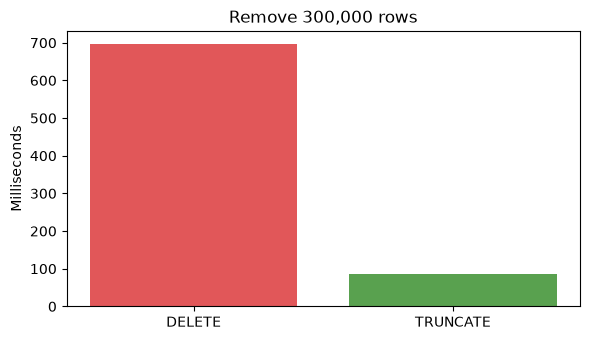

{'DELETE': '696 ms', 'TRUNCATE': '86 ms'}


In [6]:
import time

timings = {}
for method in ("DELETE", "TRUNCATE"):
    run("DROP TABLE IF EXISTS big_log; CREATE TABLE big_log (id bigint, msg text); "
        "INSERT INTO big_log SELECT g, md5(g::text) FROM generate_series(1, 300000) g")
    t = time.perf_counter()
    run("DELETE FROM big_log" if method == "DELETE" else "TRUNCATE big_log")
    timings[method] = (time.perf_counter() - t) * 1000
run("DROP TABLE big_log")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(timings.keys(), timings.values(), color=["#E15759", "#59A14F"])
ax.set(title="Remove 300,000 rows", ylabel="Milliseconds")
plt.tight_layout()
plt.show()
print({k: f"{v:.0f} ms" for k, v in timings.items()})

`DELETE` removes rows one by one and records each removal; `TRUNCATE` releases the whole storage at once.

*Insight: Put the rules of your data into the schema: types, `NOT NULL`, `UNIQUE`, `CHECK` and foreign keys. Application code changes and has bugs; a constraint in the database protects the data from every program that writes to it.*

## Real-World Use Case or Analogy

A schema is like the **form design of a government office**. A well-designed form has boxes of the right size, marks the required fields, accepts only valid dates, and refers to other forms by their number. A bad form accepts anything, and the office spends months cleaning the data.

When companies migrate to a new database or build a data warehouse, most effort goes into schema design and data-quality rules. Tools such as dbt (M11) bring the same ideas (tests for uniqueness, not-null and accepted values) to analytics tables.